# 03 Correction CNN, diffusion model, calibration and reserve sizing

Needs the outputs of notebooks 01 and 02. Contents:
1. Correction CNN, which predicts an adjustment to smart persistence (three seeds).
2. Two extra seeds for the A5 feature set, to check whether it beats A4.
3. Conditional diffusion model on the full test set, predicting either PV or the correction to smart persistence.
4. Split conformal calibration on the validation days.
5. Reserve sizing at 95% reliability.

In [1]:
!pip install -q datasets pvlib
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/UROP'
LOCAL_CACHE = '/content/skippd_cache'

Mounted at /content/drive


In [2]:
import os, shutil, time, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
os.makedirs(f'{OUT}/figs', exist_ok=True); os.makedirs(f'{OUT}/ckpt', exist_ok=True)
os.makedirs(f'{OUT}/cache', exist_ok=True); os.makedirs(LOCAL_CACHE, exist_ok=True)
SEED = 42
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


In [3]:
INPUT_LEN, HORIZON = 15, 15
LAT, LON, ALT = 37.4275, -122.1697, 23
PANEL_TILT, PANEL_AZIMUTH, PANEL_KW_DC = 22.5, 195, 30.1
PV_CAP_PCT = 99.95
RUN = 'day3'
TRAIN = dict(batch=256, lr=1e-3, max_epochs=25, patience=4, val_frac_days=0.15)

SEL_NAME = 'A4 + PV variability'
SEL_C = dict(geo=True, cs=True, kout=True, var=True)
A5_C = dict(geo=True, cs=True, kout=True, var=True, motion=True)
ENSEMBLE_SEEDS = [0, 1, 2, 3, 4]
A5_EXTRA_SEEDS = [1, 2]
RESID_SEEDS = [0, 1, 2]
MC_PASSES = 30
DIFF = dict(T=100, max_epochs=15, patience=4, lr=2e-4, batch=512, n_samples=50)
RUN_DIRECT_DIFFUSION = True
ALPHA = 0.10
RESERVE_LEVEL = 0.95

RESULTS_CSV = f'{OUT}/results.csv'
RESULT_COLS = ['when','run','train_data','test_set','model','n','rmse','mae','skill_rmse_vs_smart','skill_mae_vs_smart','notes']
def log_result(**row):
    row['when'] = pd.Timestamp.now().isoformat(timespec='seconds')
    pd.DataFrame([{c: row.get(c, '') for c in RESULT_COLS}]).to_csv(RESULTS_CSV, mode='a', header=not os.path.exists(RESULTS_CSV), index=False)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items() if k not in ('when', 'run')})

## 1. Data, clock correction, baselines and features

In [4]:
def load_split(split):
    names = ['img', 'pv', 'ts']
    local = {k: f'{LOCAL_CACHE}/{split}_{k}.npy' for k in names}
    drive_ = {k: f'{OUT}/cache/{split}_{k}.npy' for k in names}

    if not all(os.path.exists(p) for p in local.values()) and all(os.path.exists(p) for p in drive_.values()):
        print(f'[{split}] copying cache from Drive to local disk...')
        for k in names: shutil.copy(drive_[k], local[k])

    if all(os.path.exists(p) for p in local.values()):
        print(f'[{split}] loading from cache')
        img = np.load(local['img']); pv = np.load(local['pv']); ts_raw = np.load(local['ts'])
    else:
        from datasets import load_dataset
        print(f'[{split}] downloading from Hugging Face (first run only)...')
        ds = load_dataset('solarbench/SKIPPD', split=split)
        n = len(ds)
        img = np.empty((n, 64, 64, 3), dtype=np.uint8)
        pos = 0
        t0 = time.time()
        for b in ds.iter(batch_size=2000):
            arr = np.stack([np.asarray(im.convert('RGB')) for im in b['image']])
            img[pos:pos + len(arr)] = arr
            pos += len(arr)
            if pos % 50000 < 2000: print(f'  {pos}/{n} images  ({time.time()-t0:.0f}s)')
        pv = np.asarray(ds['pv'], dtype=np.float32)
        t = pd.to_datetime(ds['time'])
        if t.tz is not None:
            t = t.tz_convert('UTC').tz_localize(None)
        ts_raw = t.values.astype('datetime64[ns]')
        for k, v in [('img', img), ('pv', pv), ('ts', ts_raw)]:
            np.save(local[k], v); shutil.copy(local[k], drive_[k])
        print(f'[{split}] cached to Drive')

    order = np.argsort(ts_raw, kind='stable')
    return dict(name=split, img=img, img_idx=order, pv=pv[order].astype(np.float32),
                ts=pd.DatetimeIndex(ts_raw[order]))

In [5]:
TR = load_split('train'); TE = load_split('test')
prep_path = f'{OUT}/day1b_prep.npz'
assert os.path.exists(prep_path), 'Run notebook 01 first: it creates day1b_prep.npz'
P = np.load(prep_path, allow_pickle=True)
TR['w_clean'] = P['tr_w_clean']; TE['w_clean'] = P['te_w_clean']; TE['w_raw'] = P['te_w_raw']
print('train clean windows:', len(TR['w_clean']), '| test clean:', len(TE['w_clean']), '| test raw:', len(TE['w_raw']))

[train] copying cache from Drive to local disk...
[train] loading from cache
[test] copying cache from Drive to local disk...
[test] loading from cache
train clean windows: 320172 | test clean: 12777 | test raw: 13392


In [6]:
from pvlib.location import Location
from pvlib import irradiance
SITE = Location(LAT, LON, altitude=ALT)
TZ = 'UTC'

def solar_terms(ts_naive, tz='UTC'):
    idx = pd.DatetimeIndex(ts_naive)
    aware = idx.tz_localize('UTC') if tz == 'UTC' else idx.tz_localize(tz, ambiguous='NaT', nonexistent='NaT')
    ok = ~aware.isna()
    out = [np.full(len(idx), np.nan, dtype=np.float32) for _ in range(3)]
    a = aware[ok]
    cs = SITE.get_clearsky(a, model='ineichen'); sp = SITE.get_solarposition(a)
    poa = irradiance.get_total_irradiance(PANEL_TILT, PANEL_AZIMUTH, dni=cs['dni'], ghi=cs['ghi'], dhi=cs['dhi'],
                                          solar_zenith=sp['apparent_zenith'], solar_azimuth=sp['azimuth'])
    out[0][ok] = np.clip(PANEL_KW_DC * poa['poa_global'].values / 1000.0, 0, PANEL_KW_DC)
    out[1][ok] = sp['apparent_zenith'].values
    out[2][ok] = sp['azimuth'].values
    return out

def local_date(ts):
    return np.array((pd.DatetimeIndex(ts) - pd.Timedelta(hours=8)).date)

def is_dst(d):
    return bool((pd.Timestamp(d) + pd.Timedelta(hours=12)).tz_localize('America/Los_Angeles').dst())

FIX_PATH = f'{OUT}/clock_fix.json'
if os.path.exists(FIX_PATH):
    CLOCK_FIX = json.load(open(FIX_PATH)); print('clock fix loaded:', CLOCK_FIX)
else:
    ld = local_date(TR['ts'])
    df = pd.DataFrame({'pv': TR['pv'], 'd': ld}, index=TR['ts'])
    rough = {d: np.abs(np.diff(g.pv.values)).sum() / max(g.pv.sum(), 1e-6)
             for d, g in df.groupby('d') if len(g) >= 300 and g.pv.max() >= 15}
    rough = pd.Series(rough).sort_values()
    picks = pd.DataFrame({'day': rough.index}).assign(m=lambda x: [(d.year, d.month) for d in x.day]).groupby('m').head(3).day
    rows = []
    for d in picks:
        p = df.pv[ld == d]; p.index = p.index.floor('min'); p = p[~p.index.duplicated()]
        grid = pd.date_range(p.index.min() - pd.Timedelta(minutes=150), p.index.max() + pd.Timedelta(minutes=150), freq='1min')
        cs = pd.Series(solar_terms(grid)[0], index=grid); pv_g = p.reindex(grid)
        best = (0, -2.0)
        for L in range(-120, 125, 5):
            c = cs.shift(L); ok = pv_g.notna() & c.notna()
            if ok.sum() < 100: continue
            r = np.corrcoef(pv_g[ok], c[ok])[0, 1]
            if r > best[1]: best = (L, r)
        rows.append(dict(day=d, dst=is_dst(d), lag=best[0], corr=best[1]))
    lag = pd.DataFrame(rows); good = lag[lag['corr'] >= 0.95]
    m_dst, m_std = good[good.dst].lag.median(), good[~good.dst].lag.median()
    print(f'{len(good)}/{len(lag)} clear days usable. Median shift: daylight saving {m_dst} min, standard {m_std} min')
    std = int(5 * round(m_std / 5)) if abs(m_std) >= 15 else 0
    CLOCK_FIX = {'dst_min': std + 60 * int(round((m_dst - m_std) / 60)), 'std_min': std}
    json.dump(CLOCK_FIX, open(FIX_PATH, 'w')); lag.to_csv(f'{OUT}/clock_offset_by_day_v2.csv', index=False)
    print('clock fix:', CLOCK_FIX)

def solar_time(ts):
    ts = pd.DatetimeIndex(ts); ld = local_date(ts)
    lut = {d: is_dst(d) for d in set(ld)}
    shift = np.where(np.array([lut[d] for d in ld]), CLOCK_FIX['dst_min'], CLOCK_FIX['std_min'])
    return ts - pd.to_timedelta(shift, unit='min')

for D in (TR, TE):
    cs, zen, azi = solar_terms(solar_time(D['ts']))
    D['cs_raw'] = np.nan_to_num(cs); D['zen'] = np.nan_to_num(zen, nan=180.0); D['azi'] = np.nan_to_num(azi)
PV_CAP = float(np.percentile(TR['pv'], PV_CAP_PCT))
for D in (TR, TE):
    D['cs'] = np.minimum(D['cs_raw'], PV_CAP).astype(np.float32)
    D['k'] = np.clip(D['pv'] / np.maximum(D['cs'], 1.0), 0, 1.5).astype(np.float32)
    doy = D['ts'].dayofyear.values
    D['doy_s'] = np.sin(2 * np.pi * doy / 365.25).astype(np.float32); D['doy_c'] = np.cos(2 * np.pi * doy / 365.25).astype(np.float32)
    D['ld'] = local_date(D['ts'])
print(f'PV cap (inverter limit estimate): {PV_CAP:.2f} kW')

clock fix loaded: {'dst_min': 60, 'std_min': 0}
PV cap (inverter limit estimate): 28.91 kW


In [7]:
def metrics(pred, true):
    return float(np.sqrt(np.mean((pred - true) ** 2))), float(np.mean(np.abs(pred - true)))

PRED = {}
SIGMA = {}
TESTS = {'raw test': TE['w_raw'], 'clean test': TE['w_clean']}
for label, w in TESTS.items():
    last = TE['pv'][w]
    PRED[('naive persistence', label)] = last
    PRED[('smart persistence', label)] = np.clip(last / np.maximum(TE['cs_raw'][w], 1e-3) * TE['cs_raw'][w + HORIZON], 0, None)
BASE = {label: metrics(PRED[('smart persistence', label)], TE['pv'][w + HORIZON]) for label, w in TESTS.items()}
for label, (r, m) in BASE.items(): print(f'smart persistence on {label}: RMSE {r:.3f}  MAE {m:.3f}')

def score(name, notes=''):
    for label, w in TESTS.items():
        y = TE['pv'][w + HORIZON]; r, m = metrics(PRED[(name, label)], y); r_s, m_s = BASE[label]
        log_result(run=RUN, train_data='clean', test_set=label, model=name, n=len(y), rmse=r, mae=m,
                   skill_rmse_vs_smart=1 - r / r_s, skill_mae_vs_smart=1 - m / m_s, notes=notes)
score('naive persistence'); score('smart persistence')

smart persistence on raw test: RMSE 3.609  MAE 1.634
smart persistence on clean test: RMSE 3.233  MAE 1.474
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'naive persistence', 'n': 13392, 'rmse': 3.743, 'mae': 2.145, 'skill_rmse_vs_smart': -0.037, 'skill_mae_vs_smart': -0.313, 'notes': ''}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'naive persistence', 'n': 12777, 'rmse': 3.375, 'mae': 1.982, 'skill_rmse_vs_smart': -0.044, 'skill_mae_vs_smart': -0.344, 'notes': ''}
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'smart persistence', 'n': 13392, 'rmse': 3.609, 'mae': 1.634, 'skill_rmse_vs_smart': 0.0, 'skill_mae_vs_smart': 0.0, 'notes': ''}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'smart persistence', 'n': 12777, 'rmse': 3.233, 'mae': 1.474, 'skill_rmse_vs_smart': 0.0, 'skill_mae_vs_smart': 0.0, 'notes': ''}


In [8]:
OFF = np.arange(-(INPUT_LEN - 1), 1)

def vec_feats(D, t, c):
    H = t[:, None] + OFF; tg = t + HORIZON
    parts = [D['pv'][H] / PV_CAP]
    if c.get('geo'):
        parts.append(np.stack([D['doy_s'][t], D['doy_c'][t], D['zen'][t] / 90, D['zen'][tg] / 90,
                               np.cos(np.radians(D['zen'][t])), np.sin(np.radians(D['azi'][t])), np.cos(np.radians(D['azi'][t]))], 1))
    if c.get('cs'):
        parts += [D['cs'][H] / PV_CAP, (D['cs'][tg] / PV_CAP)[:, None]]
    if c.get('kout'):
        parts.append(D['k'][H])
    if c.get('var'):
        kh, ph = D['k'][H], D['pv'][H]
        parts.append(np.stack([kh.std(1), np.abs(np.diff(ph, axis=1)).mean(1) / PV_CAP,
                               (ph[:, -1] - ph[:, -6]) / PV_CAP, (ph.max(1) - ph.min(1)) / PV_CAP], 1))
    return np.concatenate(parts, 1).astype(np.float32)

def to_img(D, t):
    return torch.from_numpy(D['img'][D['img_idx'][t]]).to(device).permute(0, 3, 1, 2).float().div_(255.0)

def batches(D, w, c, bs, shuffle, rng=None):
    idx = rng.permutation(len(w)) if shuffle else np.arange(len(w))
    for i in range(0, len(w), bs):
        t = w[idx[i:i + bs]]
        xv = torch.from_numpy(vec_feats(D, t, c)).to(device)
        img = to_img(D, t)
        if c.get('motion'): img = torch.cat([img, img - to_img(D, t - 5)], 1)
        cst = torch.from_numpy(D['cs'][t + HORIZON] / PV_CAP).float().to(device)
        y = torch.from_numpy(D['pv'][t + HORIZON] / PV_CAP).float().to(device)
        yield xv, img, cst, y

class FeatCNN(nn.Module):
    '''Same image branch as the notebook 01 CNN; the PV branch takes the extra feature vector.
       With kout=True it outputs a clear-sky index and the forecast is index x clear-sky PV at the target time.'''
    def __init__(self, n_vec, img_ch=3, use_image=True, kout=False, p_drop=0.2):
        super().__init__()
        self.use_image, self.kout = use_image, kout
        if use_image:
            self.conv = nn.Sequential(
                nn.Conv2d(img_ch, 16, 5, stride=2, padding=2), nn.ReLU(),
                nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
                nn.Conv2d(32, 32, 3, stride=2, padding=1), nn.ReLU(),
                nn.AdaptiveAvgPool2d(4))
        self.vec = nn.Sequential(nn.Linear(n_vec, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Linear((32 * 16 if use_image else 0) + 32, 64), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(64, 1))
    def forward(self, xv, img, cst):
        f = self.vec(xv)
        if self.use_image: f = torch.cat([self.conv(img).flatten(1), f], 1)
        out = self.head(f).squeeze(-1)
        return out * cst if self.kout else out

def n_vec(c):
    return vec_feats(TR, TR['w_clean'][:2], c).shape[1]

def split_by_days(D, w, frac, seed=SEED):
    days = D['ld'][w]; uniq = np.array(sorted(set(days)))
    val_days = set(np.random.default_rng(seed).choice(uniq, int(len(uniq) * frac), replace=False))
    m = pd.Series(days).isin(val_days).values
    return w[~m], w[m]
W_TR, W_VA = split_by_days(TR, TR['w_clean'], TRAIN['val_frac_days'])
print(f'{len(W_TR)} train / {len(W_VA)} val windows (validation = random 15% of days, same as notebook 01)')

271661 train / 48511 val windows (validation = random 15% of days, same as notebook 01)


In [9]:
def smart_base(D, t):
    '''Smart persistence, capped at the inverter limit. Used as the starting point of the correction models.'''
    return np.clip(D['pv'][t] / np.maximum(D['cs_raw'][t], 1e-3) * D['cs_raw'][t + HORIZON], 0, PV_CAP).astype(np.float32)

_vec_feats_day2 = vec_feats
def vec_feats(D, t, c):
    x = _vec_feats_day2(D, t, c)
    if c.get('resid'):
        x = np.concatenate([x, (smart_base(D, t) / PV_CAP)[:, None]], 1)
    return x

class ResidCNN(FeatCNN):
    '''Forecast = smart persistence + learned correction.'''
    def __init__(self, n_vec, img_ch=3, use_image=True):
        super().__init__(n_vec, img_ch=img_ch, use_image=use_image, kout=False)
    def forward(self, xv, img, cst):
        return xv[:, -1] + super().forward(xv, img, cst)

def make_model(c, use_image=True):
    kw = dict(img_ch=6 if c.get('motion') else 3, use_image=use_image)
    m = ResidCNN(n_vec(c), **kw) if c.get('resid') else FeatCNN(n_vec(c), kout=bool(c.get('kout')), **kw)
    return m.to(device)

for label, w in TESTS.items():
    PRED[('smart persistence (capped)', label)] = smart_base(TE, w)
score('smart persistence (capped)', notes='capped at inverter limit; the starting point of the correction models')

{'train_data': 'clean', 'test_set': 'raw test', 'model': 'smart persistence (capped)', 'n': 13392, 'rmse': 3.608, 'mae': 1.633, 'skill_rmse_vs_smart': 0.0, 'skill_mae_vs_smart': 0.0, 'notes': 'capped at inverter limit; the starting point of the correction models'}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'smart persistence (capped)', 'n': 12777, 'rmse': 3.233, 'mae': 1.474, 'skill_rmse_vs_smart': 0.0, 'skill_mae_vs_smart': 0.0, 'notes': 'capped at inverter limit; the starting point of the correction models'}


In [10]:
def train_run(tag, c, seed=0, use_image=True, cfg=TRAIN, prefix=None):
    ck = f'{OUT}/ckpt/{prefix or RUN}_{tag}.pt'
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = make_model(c, use_image)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=1e-4)
    st = dict(epoch=0, best=float('inf'), bad=0, hist=[], best_state=None, done=False)
    if os.path.exists(ck):
        st = torch.load(ck, map_location=device, weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt'])
        if not st.get('done'): print(f'[{tag}] resuming from epoch {st["epoch"]}')
    loss_fn = nn.MSELoss()
    while not st.get('done'):
        t0 = time.time(); model.train(); tl = []
        for xv, img, cst, y in batches(TR, W_TR, c, cfg['batch'], True, rng):
            loss = loss_fn(model(xv, img, cst), y); opt.zero_grad(); loss.backward(); opt.step(); tl.append(loss.item())
        model.eval(); vs, vn = 0.0, 0
        with torch.no_grad():
            for xv, img, cst, y in batches(TR, W_VA, c, 2048, False):
                vs += loss_fn(model(xv, img, cst), y).item() * len(y); vn += len(y)
        v = vs / vn; st['hist'].append((float(np.mean(tl)), v)); st['epoch'] += 1
        if v < st['best']:
            st['best'], st['bad'] = v, 0
            st['best_state'] = {k: x.detach().clone() for k, x in model.state_dict().items()}
        else:
            st['bad'] += 1
        st['done'] = st['epoch'] >= cfg['max_epochs'] or st['bad'] >= cfg['patience']
        st['model'], st['opt'] = model.state_dict(), opt.state_dict()
        torch.save(st, ck)
        print(f'[{tag}] epoch {st["epoch"]:2d}  train {np.mean(tl):.4f}  val {v:.4f}  ({time.time()-t0:.0f}s)')
    model.load_state_dict(st['best_state']); model.eval()
    return model, st

@torch.no_grad()
def predict(model, D, w, c, mc_passes=0):
    if mc_passes: model.train()
    mean, std = [], []
    for xv, img, cst, _ in batches(D, w, c, 2048, False):
        if mc_passes:
            s = torch.stack([model(xv, img, cst) for _ in range(mc_passes)])
            mean.append(s.mean(0).cpu().numpy()); std.append(s.std(0).cpu().numpy())
        else:
            mean.append(model(xv, img, cst).cpu().numpy())
    model.eval()
    m = np.concatenate(mean) * PV_CAP
    return (m, np.concatenate(std) * PV_CAP) if mc_passes else m

## 2. Ensemble and MC dropout predictions from notebook 02

In [11]:
VAL = W_VA
y_val = TR['pv'][VAL + HORIZON]
VPRED, VSIG = {}, {}
mem_t = {label: [] for label in TESTS}; mem_v = []
for s in ENSEMBLE_SEEDS:
    tag = 'A4' if s == 0 else f'A4_seed{s}'
    m, _ = train_run(tag, SEL_C, seed=s, prefix='feat')
    for label, w in TESTS.items(): mem_t[label].append(predict(m, TE, w, SEL_C))
    mem_v.append(predict(m, TR, VAL, SEL_C))
    if s == 0:
        PRED[('A4 single model', 'raw test')], PRED[('A4 single model', 'clean test')] = mem_t['raw test'][0], mem_t['clean test'][0]
        VPRED['A4 single model'] = mem_v[0]
        for label, w in TESTS.items():
            PRED[('MC dropout', label)], SIGMA[('MC dropout', label)] = predict(m, TE, w, SEL_C, mc_passes=MC_PASSES)
        VPRED['MC dropout'], VSIG['MC dropout'] = predict(m, TR, VAL, SEL_C, mc_passes=MC_PASSES)
    del m; torch.cuda.empty_cache()
for label in TESTS:
    st = np.stack(mem_t[label]); PRED[('deep ensemble', label)] = st.mean(0); SIGMA[('deep ensemble', label)] = st.std(0)
st = np.stack(mem_v); VPRED['deep ensemble'] = st.mean(0); VSIG['deep ensemble'] = st.std(0)
for n in ['A4 single model', 'deep ensemble', 'MC dropout']: score(n, notes='Day 2 checkpoints')

{'train_data': 'clean', 'test_set': 'raw test', 'model': 'A4 single model', 'n': 13392, 'rmse': 3.003, 'mae': 1.625, 'skill_rmse_vs_smart': 0.168, 'skill_mae_vs_smart': 0.005, 'notes': 'Day 2 checkpoints'}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'A4 single model', 'n': 12777, 'rmse': 2.759, 'mae': 1.508, 'skill_rmse_vs_smart': 0.147, 'skill_mae_vs_smart': -0.023, 'notes': 'Day 2 checkpoints'}
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'deep ensemble', 'n': 13392, 'rmse': 2.943, 'mae': 1.575, 'skill_rmse_vs_smart': 0.185, 'skill_mae_vs_smart': 0.036, 'notes': 'Day 2 checkpoints'}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'deep ensemble', 'n': 12777, 'rmse': 2.698, 'mae': 1.456, 'skill_rmse_vs_smart': 0.166, 'skill_mae_vs_smart': 0.013, 'notes': 'Day 2 checkpoints'}
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'MC dropout', 'n': 13392, 'rmse': 3.005, 'mae': 1.629, 'skill_rmse_vs_smart': 0.167, 'skill_mae_vs_smart': 0.003, 'not

## 3. A5 seed check

In [12]:
a5_t = {label: [] for label in TESTS}
for s in [0] + A5_EXTRA_SEEDS:
    tag = 'A5' if s == 0 else f'A5_seed{s}'
    m, _ = train_run(tag, A5_C, seed=s, prefix='feat' if s == 0 else RUN)
    for label, w in TESTS.items(): a5_t[label].append(predict(m, TE, w, A5_C))
    del m; torch.cuda.empty_cache()
rows = []
for label, w in TESTS.items():
    y = TE['pv'][w + HORIZON]
    for name, preds in [('A4 + PV variability (5 seeds)', mem_t[label]), ('A5 + cloud motion (3 seeds)', a5_t[label])]:
        r = np.array([metrics(p, y) for p in preds])
        rows.append(dict(test_set=label, config=name, rmse_mean=r[:, 0].mean(), rmse_std=r[:, 0].std(), mae_mean=r[:, 1].mean(), mae_std=r[:, 1].std()))
a5 = pd.DataFrame(rows); print(a5.round(3).to_string(index=False)); a5.to_csv(f'{OUT}/day3_a5_seed_check.csv', index=False)
print('If the A5 - A4 gap is several times the std, cloud motion genuinely helps. A4 remains the pre-registered choice.')

[A5_seed1] epoch  1  train 0.0071  val 0.0042  (13s)
[A5_seed1] epoch  2  train 0.0050  val 0.0042  (12s)
[A5_seed1] epoch  3  train 0.0044  val 0.0041  (12s)
[A5_seed1] epoch  4  train 0.0040  val 0.0040  (12s)
[A5_seed1] epoch  5  train 0.0038  val 0.0041  (13s)
[A5_seed1] epoch  6  train 0.0036  val 0.0040  (13s)
[A5_seed1] epoch  7  train 0.0034  val 0.0041  (13s)
[A5_seed1] epoch  8  train 0.0033  val 0.0042  (13s)
[A5_seed2] epoch  1  train 0.0094  val 0.0043  (13s)
[A5_seed2] epoch  2  train 0.0059  val 0.0045  (13s)
[A5_seed2] epoch  3  train 0.0050  val 0.0042  (13s)
[A5_seed2] epoch  4  train 0.0045  val 0.0043  (13s)
[A5_seed2] epoch  5  train 0.0041  val 0.0043  (13s)
[A5_seed2] epoch  6  train 0.0039  val 0.0042  (13s)
[A5_seed2] epoch  7  train 0.0037  val 0.0040  (13s)
[A5_seed2] epoch  8  train 0.0036  val 0.0044  (13s)
[A5_seed2] epoch  9  train 0.0034  val 0.0044  (13s)
[A5_seed2] epoch 10  train 0.0033  val 0.0043  (13s)
[A5_seed2] epoch 11  train 0.0031  val 0.0045 

## 4. Correction CNN

In [13]:
R_C = dict(SEL_C, resid=True)
r_t = {label: [] for label in TESTS}; r_v = []
for s in RESID_SEEDS:
    m, _ = train_run(f'R4_seed{s}', R_C, seed=s)
    for label, w in TESTS.items(): r_t[label].append(predict(m, TE, w, R_C))
    r_v.append(predict(m, TR, VAL, R_C))
    del m; torch.cuda.empty_cache()
for label in TESTS:
    PRED[('correction CNN', label)] = r_t[label][0]
    st = np.stack(r_t[label]); PRED[('correction CNN, 3-seed ensemble', label)] = st.mean(0); SIGMA[('correction CNN, 3-seed ensemble', label)] = st.std(0)
VPRED['correction CNN'] = r_v[0]
st = np.stack(r_v); VPRED['correction CNN, 3-seed ensemble'] = st.mean(0); VSIG['correction CNN, 3-seed ensemble'] = st.std(0)
score('correction CNN', notes='A4 features, forecast = smart persistence + correction, seed 0')
score('correction CNN, 3-seed ensemble', notes='A4 features')

[R4_seed0] epoch  1  train 0.0046  val 0.0042  (9s)
[R4_seed0] epoch  2  train 0.0039  val 0.0047  (9s)
[R4_seed0] epoch  3  train 0.0038  val 0.0042  (9s)
[R4_seed0] epoch  4  train 0.0036  val 0.0044  (9s)
[R4_seed0] epoch  5  train 0.0035  val 0.0044  (12s)
[R4_seed1] epoch  1  train 0.0044  val 0.0041  (9s)
[R4_seed1] epoch  2  train 0.0038  val 0.0040  (9s)
[R4_seed1] epoch  3  train 0.0037  val 0.0042  (9s)
[R4_seed1] epoch  4  train 0.0035  val 0.0041  (9s)
[R4_seed1] epoch  5  train 0.0034  val 0.0041  (9s)
[R4_seed1] epoch  6  train 0.0032  val 0.0043  (9s)
[R4_seed2] epoch  1  train 0.0045  val 0.0046  (9s)
[R4_seed2] epoch  2  train 0.0038  val 0.0042  (9s)
[R4_seed2] epoch  3  train 0.0036  val 0.0041  (10s)
[R4_seed2] epoch  4  train 0.0035  val 0.0044  (9s)
[R4_seed2] epoch  5  train 0.0033  val 0.0042  (9s)
[R4_seed2] epoch  6  train 0.0031  val 0.0044  (9s)
[R4_seed2] epoch  7  train 0.0029  val 0.0047  (9s)
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'corr

## 5. Conditional diffusion model
Same encoder as the CNN. The conditioning is computed once per window and reused for all samples and denoising steps.

At every denoising step the estimate of the clean target is clipped to [0, PV cap] before the next step is drawn.

In [14]:
def cosine_betas(T, s=0.008):
    x = torch.linspace(0, T, T + 1)
    ac = torch.cos(((x / T) + s) / (1 + s) * math.pi * 0.5) ** 2; ac = ac / ac[0]
    return torch.clip(1 - ac[1:] / ac[:-1], 1e-4, 0.999)
BETAS = cosine_betas(DIFF['T']).to(device); ALPHAS = 1 - BETAS; ACP = torch.cumprod(ALPHAS, 0)

def t_embed(t, dim=16):
    half = dim // 2
    f = torch.exp(-math.log(10000) * torch.arange(half, device=t.device).float() / half)
    a = t.float()[:, None] * f[None]
    return torch.cat([torch.sin(a), torch.cos(a)], -1)

class DiffNet(nn.Module):
    def __init__(self, n_vec, img_ch=3):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(img_ch, 16, 5, stride=2, padding=2), nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(4))
        self.vec = nn.Sequential(nn.Linear(n_vec, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU())
        self.den = nn.Sequential(nn.Linear(1 + 16 + 32 * 16 + 32, 256), nn.SiLU(), nn.Linear(256, 128), nn.SiLU(), nn.Linear(128, 1))
    def context(self, xv, img):
        return torch.cat([self.conv(img).flatten(1), self.vec(xv)], 1)
    def denoise(self, z, t, ctx):
        return self.den(torch.cat([z[:, None], t_embed(t), ctx], 1)).squeeze(-1)

D_C = dict(SEL_C, resid=True)
y_tr_n = TR['pv'][W_TR + HORIZON] / PV_CAP
sp_tr_n = smart_base(TR, W_TR) / PV_CAP
NORM = {'resid': (0.0, float((y_tr_n - sp_tr_n).std())), 'direct': (float(y_tr_n.mean()), float(y_tr_n.std()))}
print('target scaling:', NORM)

def to_z(mode, y, xv):
    mu, sd = NORM[mode]
    return ((y - xv[:, -1]) if mode == 'resid' else (y - mu)) / sd

def from_z(mode, z, xv):
    mu, sd = NORM[mode]
    return (xv[:, -1:] + z * sd) if mode == 'resid' else (mu + z * sd)

def diff_loss(model, mode, xv, img, y, gen=None):
    z0 = to_z(mode, y, xv); B = len(z0)
    t = torch.randint(0, DIFF['T'], (B,), device=device, generator=gen)
    eps = torch.randn(B, device=device, generator=gen)
    zt = ACP[t].sqrt() * z0 + (1 - ACP[t]).sqrt() * eps
    return ((model.denoise(zt, t, model.context(xv, img)) - eps) ** 2).mean()

def train_diffusion(mode):
    ck = f'{OUT}/ckpt/{RUN}_diffusion_{mode}.pt'
    torch.manual_seed(0); rng = np.random.default_rng(0)
    model = DiffNet(n_vec(D_C)).to(device); opt = torch.optim.AdamW(model.parameters(), lr=DIFF['lr'], weight_decay=1e-4)
    st = dict(epoch=0, best=float('inf'), bad=0, hist=[], best_state=None, done=False)
    if os.path.exists(ck):
        st = torch.load(ck, map_location=device, weights_only=False); model.load_state_dict(st['model']); opt.load_state_dict(st['opt'])
    while not st['done']:
        t0 = time.time(); model.train(); tl = []
        for xv, img, cst, y in batches(TR, W_TR, D_C, DIFF['batch'], True, rng):
            loss = diff_loss(model, mode, xv, img, y); opt.zero_grad(); loss.backward(); opt.step(); tl.append(loss.item())
        model.eval(); gen = torch.Generator(device=device).manual_seed(123); vs, vn = 0.0, 0
        with torch.no_grad():
            for xv, img, cst, y in batches(TR, W_VA, D_C, 4096, False):
                vs += diff_loss(model, mode, xv, img, y, gen).item() * len(y); vn += len(y)
        v = vs / vn; st['hist'].append((float(np.mean(tl)), v)); st['epoch'] += 1
        if v < st['best']:
            st['best'], st['bad'] = v, 0; st['best_state'] = {k: x.detach().clone() for k, x in model.state_dict().items()}
        else:
            st['bad'] += 1
        st['done'] = st['epoch'] >= DIFF['max_epochs'] or st['bad'] >= DIFF['patience']
        st['model'], st['opt'] = model.state_dict(), opt.state_dict(); torch.save(st, ck)
        print(f'[diffusion {mode}] epoch {st["epoch"]:2d}  train {np.mean(tl):.4f}  val {v:.4f}  ({time.time()-t0:.0f}s)')
    model.load_state_dict(st['best_state']); model.eval()
    return model, st

@torch.no_grad()
def diff_sample(model, mode, D, w, n=DIFF['n_samples'], bs=512, seed=0):
    torch.manual_seed(seed); out = []
    for xv, img, cst, y in batches(D, w, D_C, bs, False):
        ctx = model.context(xv, img); B = len(ctx)
        ctx_r = ctx.repeat_interleave(n, 0); z = torch.randn(B * n, device=device)
        lo_z = to_z(mode, torch.zeros(B, device=device), xv).repeat_interleave(n, 0)
        hi_z = to_z(mode, torch.ones(B, device=device), xv).repeat_interleave(n, 0)
        for k in reversed(range(DIFF['T'])):
            tt = torch.full((B * n,), k, device=device, dtype=torch.long)
            eps = model.denoise(z, tt, ctx_r)
            ac, ac_prev = ACP[k], (ACP[k - 1] if k > 0 else torch.tensor(1.0, device=device))
            x0 = ((z - (1 - ac).sqrt() * eps) / ac.sqrt())
            x0 = torch.maximum(torch.minimum(x0, hi_z), lo_z)
            mean = (ac_prev.sqrt() * BETAS[k] / (1 - ac)) * x0 + (ALPHAS[k].sqrt() * (1 - ac_prev) / (1 - ac)) * z
            if k > 0:
                var = BETAS[k] * (1 - ac_prev) / (1 - ac)
                z = mean + var.sqrt() * torch.randn_like(z)
            else:
                z = x0
        yhat = from_z(mode, z.view(B, n), xv).clamp(0, 1) * PV_CAP
        out.append(yhat.cpu().numpy())
    return np.concatenate(out)

SAMPLES, VSAMPLES = {}, {}
modes = ['resid'] + (['direct'] if RUN_DIRECT_DIFFUSION else [])
for mode in modes:
    name = 'diffusion (correction)' if mode == 'resid' else 'diffusion (direct)'
    sp_path = f'{OUT}/{RUN}_samples_{mode}.npz'
    if os.path.exists(sp_path):
        z = np.load(sp_path); SAMPLES[(name, 'raw test')], SAMPLES[(name, 'clean test')], VSAMPLES[name] = z['raw'], z['clean'], z['val']
        print(f'{name}: samples loaded from Drive')
    else:
        model, _ = train_diffusion(mode)
        t0 = time.time()
        SAMPLES[(name, 'raw test')] = diff_sample(model, mode, TE, TESTS['raw test'])
        SAMPLES[(name, 'clean test')] = diff_sample(model, mode, TE, TESTS['clean test'])
        VSAMPLES[name] = diff_sample(model, mode, TR, VAL)
        np.savez_compressed(sp_path, raw=SAMPLES[(name, 'raw test')], clean=SAMPLES[(name, 'clean test')], val=VSAMPLES[name])
        print(f'{name}: sampled in {time.time()-t0:.0f}s'); del model; torch.cuda.empty_cache()
    for label in TESTS:
        PRED[(name, label)] = SAMPLES[(name, label)].mean(1); SIGMA[(name, label)] = SAMPLES[(name, label)].std(1)
    VPRED[name] = VSAMPLES[name].mean(1); VSIG[name] = VSAMPLES[name].std(1)
    score(name, notes=f'{DIFF["n_samples"]} samples, T={DIFF["T"]}, full test set')

target scaling: {'resid': (0.0, 0.07521378248929977), 'direct': (0.484294593334198, 0.2590951919555664)}
[diffusion resid] epoch  1  train 0.5689  val 0.4914  (10s)
[diffusion resid] epoch  2  train 0.4380  val 0.4064  (9s)
[diffusion resid] epoch  3  train 0.3767  val 0.3527  (9s)
[diffusion resid] epoch  4  train 0.3439  val 0.3384  (9s)
[diffusion resid] epoch  5  train 0.3201  val 0.3101  (9s)
[diffusion resid] epoch  6  train 0.2956  val 0.2787  (9s)
[diffusion resid] epoch  7  train 0.2670  val 0.2595  (9s)
[diffusion resid] epoch  8  train 0.2494  val 0.2405  (9s)
[diffusion resid] epoch  9  train 0.2389  val 0.2320  (9s)
[diffusion resid] epoch 10  train 0.2338  val 0.2289  (9s)
[diffusion resid] epoch 11  train 0.2281  val 0.2221  (9s)
[diffusion resid] epoch 12  train 0.2262  val 0.2202  (9s)
[diffusion resid] epoch 13  train 0.2214  val 0.2161  (9s)
[diffusion resid] epoch 14  train 0.2172  val 0.2121  (9s)
[diffusion resid] epoch 15  train 0.2141  val 0.2196  (9s)
diffusion

## 6. Calibration
- Gaussian methods: interval = mean ± k·std, with k chosen on validation days.
- Diffusion: 5th to 95th percentile of the samples, adjusted by a conformal margin.
- Point forecasts: a fixed-width conformal band.

In [15]:
from scipy.stats import norm
VPRED['smart persistence (capped)'] = smart_base(TR, VAL)
GAUSS = ['deep ensemble', 'MC dropout', 'correction CNN, 3-seed ensemble']
SAMP = [n for n in ['diffusion (correction)', 'diffusion (direct)'] if n in VPRED]
POINT = ['smart persistence (capped)', 'correction CNN']

def sig_eff(name, sig):
    '''Spread plus a floor (median validation spread), so near-zero spreads cannot blow up the conformal factor.'''
    return np.asarray(sig) + float(np.median(VSIG[name]))

def conf_q(scores, level):
    n = len(scores); return float(np.quantile(scores, min(1.0, math.ceil((n + 1) * level) / n)))

def interval(name, label, level=1 - ALPHA, conformal=True):
    '''Return (lo, hi) on the test set for a two-sided interval at this level.'''
    a = (1 - level) / 2
    if name in GAUSS:
        mu = PRED[(name, label)]
        if not conformal:
            sg = np.maximum(SIGMA[(name, label)], 1e-6); k = norm.ppf(1 - a); return mu - k * sg, mu + k * sg
        sg = sig_eff(name, SIGMA[(name, label)])
        k = conf_q(np.abs(y_val - VPRED[name]) / sig_eff(name, VSIG[name]), level)
        return mu - k * sg, mu + k * sg
    if name in SAMP:
        s = SAMPLES[(name, label)]; lo, hi = np.quantile(s, a, 1), np.quantile(s, 1 - a, 1)
        if conformal:
            vl, vh = np.quantile(VSAMPLES[name], a, 1), np.quantile(VSAMPLES[name], 1 - a, 1)
            q = conf_q(np.maximum(vl - y_val, y_val - vh), level); lo, hi = lo - q, hi + q
        return lo, hi
    q = conf_q(np.abs(y_val - VPRED[name]), level)
    return PRED[(name, label)] - q, PRED[(name, label)] + q

def crps_samples(s, y, chunk=2000):
    tot = 0.0
    for i in range(0, len(y), chunk):
        a, b = s[i:i + chunk], y[i:i + chunk]
        tot += (np.abs(a - b[:, None]).mean(1) - 0.5 * np.abs(a[:, :, None] - a[:, None, :]).mean((1, 2))).sum()
    return tot / len(y)

def crps_gauss(mu, sg, y):
    sg = np.maximum(sg, 1e-6); z = (y - mu) / sg
    return float(np.mean(sg * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))))

In [16]:
def day_classes(D):
    day = D['zen'] < 80
    df = pd.DataFrame({'d': D['ld'][day], 'pv': D['pv'][day], 'cs': D['cs'][day], 'k': D['k'][day]})
    g = df.groupby('d')
    mean_k = g.pv.sum() / g.cs.sum().clip(lower=1e-6)
    var_k = g.k.apply(lambda s: np.abs(np.diff(s.values)).mean() if len(s) > 1 else np.nan)
    cls = pd.Series(np.where((var_k < 0.01) & (mean_k > 0.7), 'clear', np.where(mean_k < 0.45, 'overcast', 'partly cloudy')), index=mean_k.index)
    return cls, var_k
CLS, VARK = day_classes(TE)
KINDS = ['clear', 'partly cloudy', 'overcast']

rows = []
label = 'clean test'; w = TESTS[label]; y = TE['pv'][w + HORIZON]; wcls = pd.Series(TE['ld'][w]).map(CLS).values
for name in GAUSS + SAMP + POINT:
    lo_r, hi_r = interval(name, label, conformal=False) if name not in POINT else (None, None)
    lo, hi = interval(name, label, conformal=True)
    crps = crps_gauss(PRED[(name, label)], SIGMA[(name, label)], y) if name in GAUSS else (crps_samples(SAMPLES[(name, label)], y) if name in SAMP else np.nan)
    row = dict(model=name, crps=crps,
               coverage_raw=np.nan if lo_r is None else float(np.mean((y >= lo_r) & (y <= hi_r))),
               coverage_conformal=float(np.mean((y >= lo) & (y <= hi))), width_conformal=float(np.mean(hi - lo)))
    for k in KINDS:
        mk = wcls == k
        row[f'cov_{k}'] = float(np.mean((y[mk] >= lo[mk]) & (y[mk] <= hi[mk]))) if mk.any() else np.nan
        row[f'width_{k}'] = float(np.mean((hi - lo)[mk])) if mk.any() else np.nan
    rows.append(row)
CAL = pd.DataFrame(rows); CAL.to_csv(f'{OUT}/day3_calibration.csv', index=False)
pd.set_option('display.width', 200)
print(CAL.round(3).to_string(index=False))
print('\ncoverage_raw = before calibration (target 0.90). After conformal, compare widths: narrower = more useful.')

                          model  crps  coverage_raw  coverage_conformal  width_conformal  cov_clear  width_clear  cov_partly cloudy  width_partly cloudy  cov_overcast  width_overcast
                  deep ensemble 1.305         0.482               0.794            4.011      0.999        3.397              0.572                4.551         0.656           5.935
                     MC dropout 1.369         0.505               0.783            4.380      1.000        4.384              0.552                4.259         0.603           5.828
correction CNN, 3-seed ensemble 1.221         0.370               0.829            3.734      1.000        1.988              0.656                5.647         0.575           4.587
         diffusion (correction) 0.963         0.934               0.910            5.524      0.961        0.698              0.853               10.444         0.904          12.374
             diffusion (direct) 1.030         0.932               0.879            4.

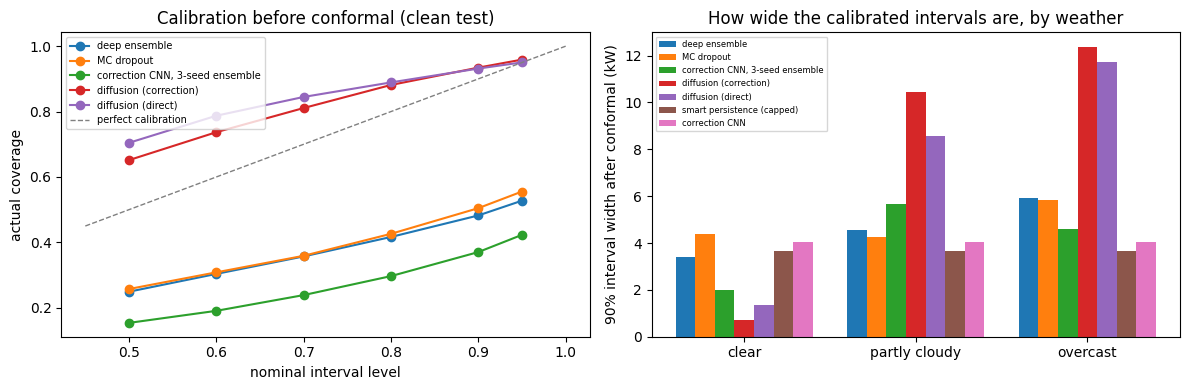

In [17]:
levels = np.array([0.5, 0.6, 0.7, 0.8, 0.9, 0.95])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
for name in GAUSS + SAMP:
    cov = [np.mean((y >= l) & (y <= h)) for l, h in (interval(name, label, lev, conformal=False) for lev in levels)]
    ax.plot(levels, cov, marker='o', label=name)
ax.plot([0.45, 1], [0.45, 1], color='0.5', ls='--', lw=1, label='perfect calibration')
ax.set_xlabel('nominal interval level'); ax.set_ylabel('actual coverage'); ax.set_title('Calibration before conformal (clean test)'); ax.legend(fontsize=7)
ax = axes[1]; bw = 0.8 / len(GAUSS + SAMP + POINT)
for i, name in enumerate(GAUSS + SAMP + POINT):
    r = CAL.set_index('model').loc[name]
    ax.bar(np.arange(3) + i * bw - 0.4 + bw / 2, [r[f'width_{k}'] for k in KINDS], bw, label=name)
ax.set_xticks(range(3)); ax.set_xticklabels(KINDS); ax.set_ylabel('90% interval width after conformal (kW)')
ax.set_title('How wide the calibrated intervals are, by weather'); ax.legend(fontsize=6)
fig.tight_layout(); fig.savefig(f'{OUT}/figs/day3_calibration.png', dpi=150); plt.show()

## 7. Reserve sizing
Each method gives a 95% lower bound, calibrated on validation days. The reserve is the gap between the point forecast and this bound.

                          model  shortfall_rate  mean_reserve_kw  reserve_clear  shortfall_clear  reserve_partly cloudy  shortfall_partly cloudy  reserve_overcast  shortfall_overcast
     smart persistence (capped)           0.108            1.651          1.657            0.000                  1.647                    0.224             1.619               0.192
                 correction CNN           0.117            1.960          1.964            0.000                  1.957                    0.238             1.936               0.267
                  deep ensemble           0.121            1.935          1.639            0.001                  2.196                    0.246             2.856               0.265
                     MC dropout           0.133            2.102          2.114            0.000                  2.041                    0.269             2.692               0.306
correction CNN, 3-seed ensemble           0.095            1.883          1.014      

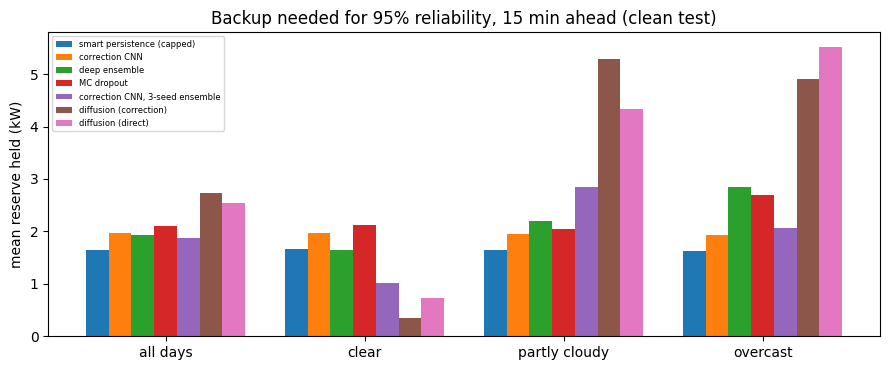

In [18]:
def lower_bound(name, label, level=RESERVE_LEVEL):
    if name in GAUSS:
        k = conf_q((VPRED[name] - y_val) / sig_eff(name, VSIG[name]), level)
        return PRED[(name, label)] - k * sig_eff(name, SIGMA[(name, label)])
    if name in SAMP:
        lo_v = np.quantile(VSAMPLES[name], 1 - level, 1); q = conf_q(lo_v - y_val, level)
        return np.quantile(SAMPLES[(name, label)], 1 - level, 1) - q
    q = conf_q(VPRED[name] - y_val, level)
    return PRED[(name, label)] - q

rows = []
for name in POINT + GAUSS + SAMP:
    lb = np.maximum(lower_bound(name, label), 0)
    reserve = np.maximum(PRED[(name, label)] - lb, 0)
    row = dict(model=name, shortfall_rate=float(np.mean(y < lb)), mean_reserve_kw=float(reserve.mean()))
    for k in KINDS:
        mk = wcls == k
        row[f'reserve_{k}'] = float(reserve[mk].mean()) if mk.any() else np.nan
        row[f'shortfall_{k}'] = float(np.mean(y[mk] < lb[mk])) if mk.any() else np.nan
    rows.append(row)
RES = pd.DataFrame(rows); RES.to_csv(f'{OUT}/day3_reserve.csv', index=False)
print(RES.round(3).to_string(index=False))
base_r = RES.set_index('model').loc['smart persistence (capped)', 'mean_reserve_kw']
print(f'\nReserve needed by smart persistence + fixed margin: {base_r:.2f} kW (target shortfall {1-RESERVE_LEVEL:.0%}).')

fig, ax = plt.subplots(figsize=(9, 3.8)); bw = 0.8 / len(RES)
for i, r in RES.reset_index(drop=True).iterrows():
    ax.bar(np.arange(4) + i * bw - 0.4 + bw / 2, [r.mean_reserve_kw] + [r[f'reserve_{k}'] for k in KINDS], bw, label=r.model)
ax.set_xticks(range(4)); ax.set_xticklabels(['all days'] + KINDS); ax.set_ylabel('mean reserve held (kW)')
ax.set_title(f'Backup needed for {RESERVE_LEVEL:.0%} reliability, 15 min ahead (clean test)'); ax.legend(fontsize=6)
fig.tight_layout(); fig.savefig(f'{OUT}/figs/day3_reserve.png', dpi=150); plt.show()

## 8. Results by weather and bootstrap intervals

In [19]:
show = ['smart persistence', 'deep ensemble', 'correction CNN, 3-seed ensemble'] + SAMP
rows = []
for name in show:
    for k in KINDS:
        mk = wcls == k
        if mk.any():
            r, m = metrics(PRED[(name, label)][mk], y[mk]); rows.append(dict(model=name, weather=k, n=int(mk.sum()), rmse=r, mae=m))
WT = pd.DataFrame(rows); WT.to_csv(f'{OUT}/day3_weather.csv', index=False)
print(WT.pivot(index='model', columns='weather', values='rmse').reindex(index=show, columns=KINDS).round(3).to_string())

def boot_ci(name, ref='smart persistence', label='clean test', n=2000, seed=0):
    w = TESTS[label]; yy = TE['pv'][w + HORIZON]; days = TE['ld'][w]
    em, er = PRED[(name, label)] - yy, PRED[(ref, label)] - yy
    g = pd.DataFrame({'d': days, 'sm': em ** 2, 'sr': er ** 2, 'am': np.abs(em), 'ar': np.abs(er), 'n': 1}).groupby('d').sum()
    idx = np.random.default_rng(seed).integers(0, len(g), (n, len(g)))
    t = lambda c: g[c].values[idx].sum(1)
    sk_r = 1 - np.sqrt(t('sm') / t('n')) / np.sqrt(t('sr') / t('n')); sk_m = 1 - t('am') / t('ar')
    return dict(model=name, vs=ref, days=len(g), rmse_skill=1 - metrics(PRED[(name, label)], yy)[0] / metrics(PRED[(ref, label)], yy)[0],
                rmse_skill_lo=np.percentile(sk_r, 2.5), rmse_skill_hi=np.percentile(sk_r, 97.5),
                mae_skill=1 - metrics(PRED[(name, label)], yy)[1] / metrics(PRED[(ref, label)], yy)[1],
                mae_skill_lo=np.percentile(sk_m, 2.5), mae_skill_hi=np.percentile(sk_m, 97.5))
B = [boot_ci(n) for n in ['deep ensemble', 'correction CNN', 'correction CNN, 3-seed ensemble'] + SAMP]
B += [boot_ci('correction CNN, 3-seed ensemble', ref='deep ensemble')] + [boot_ci(n, ref='deep ensemble') for n in SAMP]
BT = pd.DataFrame(B); BT.to_csv(f'{OUT}/day3_bootstrap.csv', index=False); print(BT.round(3).to_string(index=False))

weather                          clear  partly cloudy  overcast
model                                                          
smart persistence                0.232          4.718     3.230
deep ensemble                    0.398          3.872     3.424
correction CNN, 3-seed ensemble  0.235          3.863     3.138
diffusion (correction)           0.161          4.008     3.540
diffusion (direct)               0.280          3.964     3.616
                          model                vs  days  rmse_skill  rmse_skill_lo  rmse_skill_hi  mae_skill  mae_skill_lo  mae_skill_hi
                  deep ensemble smart persistence    20       0.166          0.113          0.207      0.013        -0.110         0.094
                 correction CNN smart persistence    20       0.157          0.126          0.181      0.050        -0.037         0.106
correction CNN, 3-seed ensemble smart persistence    20       0.175          0.136          0.208      0.083         0.016         0.137
    

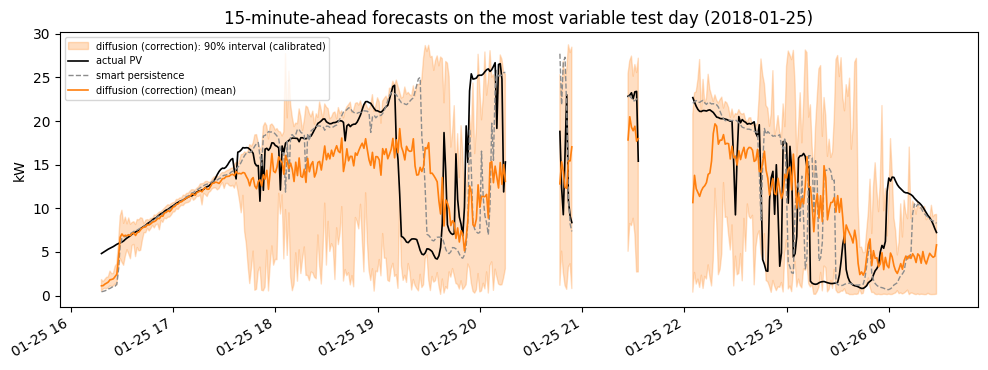

                                       mae                rmse          skill_mae_vs_smart          skill_rmse_vs_smart         
test_set                        clean test raw test clean test raw test         clean test raw test          clean test raw test
model                                                                                                                           
A4 single model                      1.508    1.625      2.759    3.003             -0.023    0.005               0.147    0.168
MC dropout                           1.511    1.629      2.760    3.005             -0.025    0.003               0.146    0.167
correction CNN                       1.401    1.526      2.726    2.986              0.050    0.066               0.157    0.173
correction CNN, 3-seed ensemble      1.353    1.478      2.669    2.926              0.083    0.095               0.175    0.189
deep ensemble                        1.456    1.575      2.698    2.943              0.013    0.0

In [20]:
best_prob = SAMP[0] if SAMP else 'deep ensemble'
lo, hi = interval(best_prob, label, conformal=True)
cand = [d for d in VARK.sort_values(ascending=False).index if (TE['ld'][w] == d).sum() > 200]
d0 = cand[0]; m = TE['ld'][w] == d0
tt = pd.Series(TE['ts'][w[m] + HORIZON])
gap = np.r_[False, (tt.diff().dt.total_seconds().values[1:] > 120)]
def br(a): a = np.asarray(a, float).copy(); a[gap] = np.nan; return a
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(tt, br(lo[m]), br(hi[m]), color='C1', alpha=.25, label=f'{best_prob}: 90% interval (calibrated)')
ax.plot(tt, br(y[m]), color='k', lw=1.2, label='actual PV')
ax.plot(tt, br(PRED[('smart persistence', label)][m]), color='0.55', lw=1, ls='--', label='smart persistence')
ax.plot(tt, br(PRED[(best_prob, label)][m]), color='C1', lw=1.2, label=f'{best_prob} (mean)')
ax.set_title(f'15-minute-ahead forecasts on the most variable test day ({d0})'); ax.set_ylabel('kW'); ax.legend(fontsize=7)
fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(f'{OUT}/figs/day3_cloudy_day.png', dpi=150); plt.show()

res = pd.read_csv(RESULTS_CSV); res = res[res.run == RUN].drop_duplicates(['test_set', 'model'], keep='last')
summary = res.pivot_table(index='model', columns='test_set', values=['rmse', 'mae', 'skill_rmse_vs_smart', 'skill_mae_vs_smart'], aggfunc='first')
summary.round(3).to_csv(f'{OUT}/day3_summary.csv'); print(summary.round(3).to_string())
print('\nDone. Saved: day3_summary.csv, day3_calibration.csv, day3_reserve.csv, day3_weather.csv, day3_bootstrap.csv, day3_a5_seed_check.csv, figs/day3_*.png')